# Loading the Libraries

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from scipy.sparse import csr_matrix

# Use a consistent style for all charts in this notebook.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

print("\n✓ Environment check passed")

Python: 3.14.2
NumPy: 2.5.3
pandas: 3.0.5

✓ Environment check passed


# Loading the data

In [3]:
# Load the dataset
df = pd.read_csv('../original_data/DataSet_AIvsHuman.csv')
df.head()


,id,prompt,content,type,source,label,topic,word_count,char_count,ai_model,language,complexity_score,is_multiline_code
0,1,Write a string manipulation solution in python,def string_manipulation():\n # TODO: implem...,code,blog,human,string manipulation,9,84,NaN,python,3,True
1,2,Explain health in simple terms,Experts recommend focusing on health to improv...,text,generated,ai,health,29,211,Claude,en,3,False
2,3,Summarize recent developments in finance,The development of finance technologies has ac...,text,generated,ai,finance,56,419,GPT-4,en,5,False
3,4,Summarize recent developments in finance,Recent studies show that finance can have sign...,text,generated,ai,finance,42,298,Claude,en,10,False
4,5,Provide a graph traversal algorithm in cpp,vector<int> arr; // graph traversal example\nf...,code,generated,ai,graph traversal,11,98,Gemini,cpp,10,True


# Splitting the data into text only

In [4]:

df_text = df[df["type"].str.lower() == "text"]
df_text.head()
print("rows, columns:", df_text.shape)

#df_text.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
#plt.tight_layout()
#plt.show()
df_text.info()

rows, columns:

 (10004, 13)
<class 'pandas.DataFrame'>
Index: 10004 entries, 1 to 19992
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   id                 10004 non-null  int64
 1   prompt             10004 non-null  str  
 2   content            10004 non-null  str  
 3   type               10004 non-null  str  
 4   source             10004 non-null  str  
 5   label              10004 non-null  str  
 6   topic              10004 non-null  str  
 7   word_count         10004 non-null  int64
 8   char_count         10004 non-null  int64
 9   ai_model           5067 non-null   str  
 10  language           10004 non-null  str  
 11  complexity_score   10004 non-null  int64
 12  is_multiline_code  10004 non-null  bool 
dtypes: bool(1), int64(4), str(8)
memory usage: 4.6 MB


# Preprocessing and Feature Engineering
## Adding Feautures

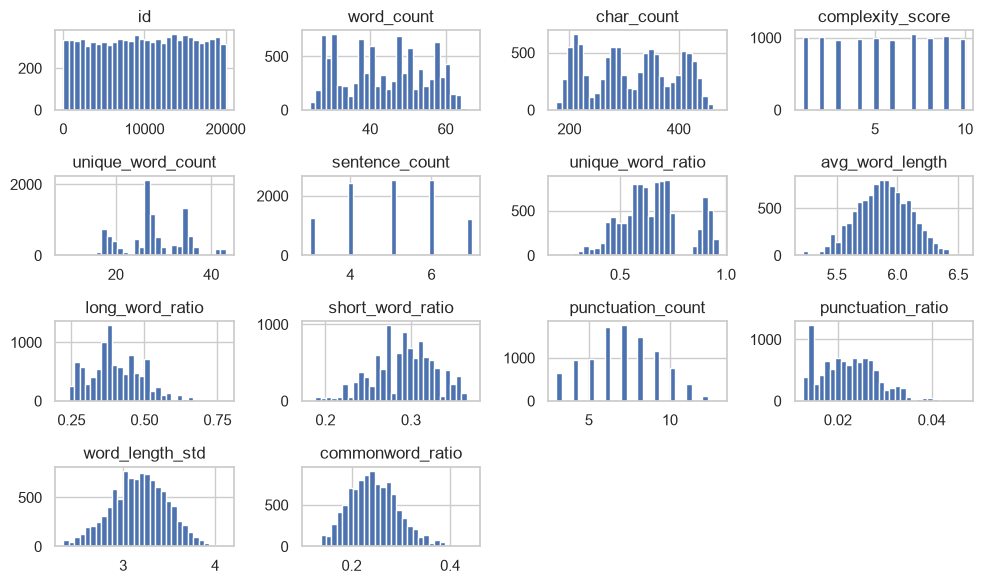

rows, columns: (10004, 23)


In [5]:
# Human vs AI Text Only Data

# Count unique words in each content entry
df_text["unique_word_count"] = df_text["content"].fillna("").apply(
    lambda text: len(
        set(
            re.findall(r"\b\w+\b", text.lower())
        )
    )
)

# Sentence count
df_text["sentence_count"] = df_text["content"].fillna("").apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x)) if s.strip()])
)

# Unique word ratio
# A low value (e.g. 0.3-0.5) indicates lots of repeated words.
# A high value (e.g. 0.8-1.0) indicates a more varied vocabulary.
df_text["unique_word_ratio"] = df_text["unique_word_count"] / df_text["word_count"].replace(0, 1)

# Average word length
df_text["avg_word_length"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(len(word) for word in re.findall(r"\b\w+\b", str(x)))
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# long word ratio
df_text["long_word_ratio"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) > 6)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# short word ratio
df_text["short_word_ratio"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) <= 3)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# punctuation count
df_text["punctuation_count"] = df_text["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
)

# punctuation ratio
df_text["punctuation_ratio"] = df_text["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
) / df_text["char_count"].replace(0, 1)

# word length standard deviation
df_text["word_length_std"] = df_text["content"].fillna("").apply(
    lambda text: np.std([
        len(word) for word in re.findall(r"\b[A-Za-z']+\b", str(text))
    ]) if re.findall(r"\b[A-Za-z']+\b", str(text)) else 0
)

# common word ratio
common_words = {
    "a", "an", "the", "and", "or", "but", "if", "is", "are", "was",
    "were", "be", "been", "being", "to", "of", "in", "on", "for",
    "with", "as", "at", "by", "from", "that", "this", "it"
}

df_text["commonword_ratio"] = df_text["content"].fillna("").apply(
    lambda text: (
        lambda words: (
            sum(word in common_words for word in words) / len(words)
            if words else 0
        )
    )(re.findall(r"\b[A-Za-z']+\b", str(text).lower()))
)

# semi-colon ratio (looked at adding it as a feature but both files had zero semicolons)

# results visualised
df_text.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

print("rows, columns:", df_text.shape)
#df_text.to_csv("../created_data/df_text.csv", index=False)

In [6]:
df_text.info()

<class 'pandas.DataFrame'>
Index: 10004 entries, 1 to 19992
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 10004 non-null  int64  
 1   prompt             10004 non-null  str    
 2   content            10004 non-null  str    
 3   type               10004 non-null  str    
 4   source             10004 non-null  str    
 5   label              10004 non-null  str    
 6   topic              10004 non-null  str    
 7   word_count         10004 non-null  int64  
 8   char_count         10004 non-null  int64  
 9   ai_model           5067 non-null   str    
 10  language           10004 non-null  str    
 11  complexity_score   10004 non-null  int64  
 12  is_multiline_code  10004 non-null  bool   
 13  unique_word_count  10004 non-null  int64  
 14  sentence_count     10004 non-null  int64  
 15  unique_word_ratio  10004 non-null  float64
 16  avg_word_length    10004 non-null  flo

## Target Leakage
> removing all non-numeric columns

In [7]:
target = "label"

leaky_cols = ["source", "ai_model", "language", "type", "is_multiline_code", "prompt", "content", "topic"]
id_cols = ["id"]

X = df_text.drop(columns=[target] + leaky_cols + id_cols)
y = df_text[target]
print("Features used:", X.columns.tolist())

X.head()
print("rows, columns:", X.shape)

Features used: ['word_count', 'char_count', 'complexity_score', 'unique_word_count', 'sentence_count', 'unique_word_ratio', 'avg_word_length', 'long_word_ratio', 'short_word_ratio', 'punctuation_count', 'punctuation_ratio', 'word_length_std', 'commonword_ratio']
rows, columns: (10004, 13)


# Train/Test Split

In [8]:
# Keep 20% of the rows aside. random_state makes this split reproducible.
# Created from 'leakagefree_data.csv'
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("train:", X_train.shape, " test:", X_test.shape)

train: (8003, 13)  test: (2001, 13)


In [9]:
X.info()

<class 'pandas.DataFrame'>
Index: 10004 entries, 1 to 19992
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   word_count         10004 non-null  int64  
 1   char_count         10004 non-null  int64  
 2   complexity_score   10004 non-null  int64  
 3   unique_word_count  10004 non-null  int64  
 4   sentence_count     10004 non-null  int64  
 5   unique_word_ratio  10004 non-null  float64
 6   avg_word_length    10004 non-null  float64
 7   long_word_ratio    10004 non-null  float64
 8   short_word_ratio   10004 non-null  float64
 9   punctuation_count  10004 non-null  int64  
 10  punctuation_ratio  10004 non-null  float64
 11  word_length_std    10004 non-null  float64
 12  commonword_ratio   10004 non-null  float64
dtypes: float64(7), int64(6)
memory usage: 1.1 MB


# Scaling numeric Values

In [10]:

numeric_cols = ["word_count",
    "char_count",
    "complexity_score",
    "unique_word_count",
    "sentence_count",
    "unique_word_ratio",
    "avg_word_length",
    "long_word_ratio",
    "short_word_ratio",
    "punctuation_count",
    "punctuation_ratio",
    "word_length_std",
    "commonword_ratio",
]
print("Ranges before scaling:")
print(X_train[numeric_cols].agg(["min", "max"]))

# The scaler learns the mean and standard deviation from training data only.
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# The test set uses those same training values; it must not calculate new ones.
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("\nTraining means after scaling:")
print(X_train[numeric_cols].mean().round(2))

Ranges before scaling:
     word_count  char_count  complexity_score  unique_word_count  \
min          24         176                 1                  9   
max          67         472                10                 43   

     sentence_count  unique_word_ratio  avg_word_length  long_word_ratio  \
min               3           0.200000         5.222222         0.222222   
max               7           0.965517         6.555556         0.777778   

     short_word_ratio  punctuation_count  punctuation_ratio  word_length_std  \
min          0.181818                  3           0.012552         2.349609   
max          0.371429                 13           0.047120         4.112612   

     commonword_ratio  
min          0.115385  
max          0.444444  

Training means after scaling:
word_count          -0.0
char_count           0.0
complexity_score    -0.0
unique_word_count   -0.0
sentence_count      -0.0
unique_word_ratio    0.0
avg_word_length     -0.0
long_word_ratio      0.0

# Train a Logistic Regression classifier

In [11]:
RANDOM_STATE = 42

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)

log_reg.fit(X_train, y_train)

log_predictions = log_reg.predict(X_test)
log_probabilities = log_reg.predict_proba(X_test)[:, 1]


print("First 20 predicted classes:", log_predictions[:20])
print("First 20 probabilities of Pass:", np.round(log_probabilities[:20], 2))
print("Test accuracy:", round(accuracy_score(y_test, log_predictions), 3))

First 20 predicted classes: ['human' 'ai' 'human' 'human' 'ai' 'human' 'human' 'ai' 'ai' 'ai' 'human'
 'human' 'ai' 'human' 'ai' 'ai' 'ai' 'ai' 'human' 'ai']
First 20 probabilities of Pass: [1.   0.   1.   1.   0.05 1.   0.95 0.08 0.01 0.   0.98 1.   0.04 1.
 0.   0.   0.   0.13 1.   0.01]
Test accuracy: 0.981


### Interpret one prediction

A probability and a predicted class are not the same thing. The class is obtained by applying a threshold to the probability (0.5 by convention). For instance, a probability of 0.51 and a probability of 0.99 both give "Pass", but the model is far more confident in the second case.

The cell below shows one student from the test set: their features, what actually happened, the model's probability, and the model's final prediction. Notice that the model can be wrong, especially when the probability is close to the threshold.

**Try it:** Change the index `i` below to inspect another test observation. Can you find a student the model got wrong?

In [ ]:
class_names = {0: "Human", 1: "AI"}
i = 0
print("Features:")
display(X_test.iloc[[i]])
print("Actual class:", class_names[int(y_test.iloc[i])])
print("Probability of Pass:", round(float(log_probabilities[i]), 3))
print("Predicted class at threshold 0.5:", class_names[int(log_predictions[i])])

# dont really understand this 

# Train a K-Nearest Neighbours classifier

### The idea

KNN is based on a simple principle: **similar students tend to have similar outcomes**. To predict for a new student:

1. Measure how far the new student is from every student in the training set (using their hours studied and attendance).
2. Pick the `k` closest students, their "nearest neighbours". Here `k = 5`.
3. Look at the neighbours' outcomes and take a **majority vote**. If 4 of the 5 neighbours passed, predict Pass.

KNN does not learn weights or draw a line. It simply stores the training data and looks things up when asked. The choice of `k` is up to us; we explore it in section 9.

### Why scaling matters here

"Distance" depends on the units of the features. Attendance ranges roughly from 35 to 100 (a spread of about 65), while study hours range from 0 to 12 (a spread of about 12). Without scaling, a difference of 10 percentage points in attendance would count the same as a difference of 10 hours of study, even though 10 hours is a huge difference and 10 percentage points is not. Attendance would dominate the distance, and study hours would be nearly ignored.

Scaling puts both features on a comparable footing, so each contributes fairly. As before, the pipeline fits the scaler on training data only.

In [18]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)
knn_predictions = knn.predict(X_test)

print("First 10 predicted classes:", knn_predictions[:10])
print("Test accuracy:", round(accuracy_score(y_test, knn_predictions), 3))

First 10 predicted classes: ['human' 'ai' 'human' 'human' 'ai' 'human' 'human' 'ai' 'ai' 'ai']
Test accuracy: 0.983


# Compare the two models

We evaluate both models on exactly the same test observations, so the comparison is fair. **Accuracy** is the proportion of test observations classified correctly. It is useful for this introduction, although it is not sufficient for every real classification problem (for example, when one class is very rare).

In [19]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN (k=5)"],
    "Test accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, knn_predictions)
    ]
}).sort_values("Test accuracy", ascending=False)

results

,Model,Test accuracy
1,KNN (k=5),0.982509
0,Logistic Regression,0.981009


# What changes when we change `k`?

In KNN, `k` is the number of neighbours that vote. It is a setting we choose ourselves, not something the model learns.

- **Small `k` (e.g. 1)**: the prediction depends on just one neighbour, so the model reacts to every individual student, including unusual ones and random noise. The boundary becomes very irregular. The model can fit the training data almost perfectly but may not work well on new students. This is called **overfitting**.
- **Large `k` (e.g. 20)**: many neighbours vote, so individual unusual students have little influence. The boundary becomes smooth, but if `k` is too large the model may ignore genuine local patterns (**underfitting**).

Train KNN with different values of `k` and compare the test accuracy and decision boundaries.

**Before running the cell, predict:** Which value of `k` will produce the most irregular boundary? Which will produce the smoothest?

In [23]:
k_values = [1, 5, 20, 300, 500, 1000, 2000, 3000, 4000, 5000]
knn_models = {}
k_results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    knn_models[k] = model
    k_results.append({
        "k": k,
        "Test accuracy": accuracy_score(y_test, predictions)
    })

pd.DataFrame(k_results)

,k,Test accuracy
0,1,0.992504
1,5,0.982509
2,20,0.969515
3,300,0.940530
4,500,0.937531
5,1000,0.936532
6,2000,0.905547
7,3000,0.883058
8,4000,0.865567
9,5000,0.821589


# Key takeaways

### Logistic Regression vs KNN

| | **Logistic Regression** | **K-Nearest Neighbours (KNN)** |
|---|---|---|
| **Main idea** | Learns a weight for each feature and combines them into a score | Finds the `k` most similar training observations and takes a majority vote |
| **What is learned** | Weights (one per feature), learned during training | Nothing: it stores the training data and looks things up at prediction time |
| **Output** | A probability of the positive class, then a class using a threshold (0.5 by convention) | A class from a vote among the neighbours |
| **Decision boundary** | A straight line (in 2 features) | Can be curvy and irregular, following local neighbourhoods |
| **Setting we choose** | The threshold (and other settings we did not use here) | `k`, the number of neighbours |
| **Effect of that setting** | Moving the threshold changes how cautious the model is about predicting Pass | Small `k`: irregular boundary, risk of overfitting. Large `k`: smooth boundary, risk of underfitting |
| **Scaling the features** | Helpful, but not essential | Important: distances depend on units, so unscaled features can dominate |
| **Interpretability** | The weights show how each feature pushes the prediction up or down | Easy to explain ("students like this one passed"), but there are no weights to inspect |
| **Prediction speed** | Fast | Slower on large datasets, since it compares against the stored training data |

